In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [3]:
emotion_dataset['train'].features['label']

ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])

In [4]:
label_names = emotion_dataset['train'].features['label'].names
label_names


['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [5]:
df_train = pd.DataFrame({
    'text': train_text,
    'label': [label_names[i] for i in train_label]
})

In [6]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [7]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [8]:
df_test = pd.DataFrame({
    'text':test_text,
    'label':[label_names[i] for i in test_label]
})

In [9]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [10]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

### Exploratory Data Analysis (EDA)

In [11]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='str', name='label')

<Axes: xlabel='label', ylabel='count'>

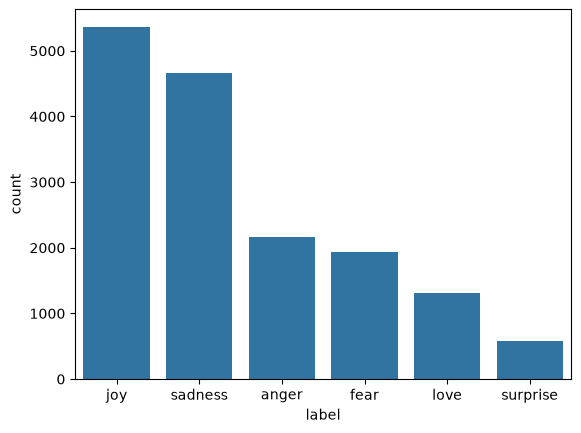

In [12]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)

In [13]:
# Data Preprocessing - Using NLP


In [14]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words,oov_token="<unk>")
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequences,maxlen=50,padding = 'post', truncating='post')
padded_test_sequence = pad_sequences(test_sequences,maxlen=50,padding = 'post',truncating = 'post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

In [15]:
num_classes = train_label.features.names

### Shared Trainig Utilities

##### compute balanced class weights to hadle dataset skew and steup eraly stopping

In [16]:
from sklearn.utils import class_weight

class_weight = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_label),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weight))

In [17]:
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [18]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience=3,
    restore_best_weights=True
)

## Phase 1- Plain Foundational Models

#### Model1 - Simple RNN

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout,LSTM,GRU

model = Sequential([
    Embedding(input_dim=max_words,output_dim = 128, input_length = 50),
    Dropout(0.5),
    SimpleRNN(units = 128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = 6,activation='softmax')
])

c:\Users\HP\anaconda3\envs\Churn\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [20]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics = ['accuracy'])

In [21]:
model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 34ms/step - accuracy: 0.1601 - loss: 2.0255 - val_accuracy: 0.1615 - val_loss: 1.8044
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.1452 - loss: 1.8811 - val_accuracy: 0.1530 - val_loss: 1.7893
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1356 - loss: 1.8238 - val_accuracy: 0.1360 - val_loss: 1.7952
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1308 - loss: 1.8073 - val_accuracy: 0.0380 - val_loss: 1.8070
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - accuracy: 0.1363 - loss: 1.8029 - val_accuracy: 0.0410 - val_loss: 1.8199


In [29]:
import tensorflow as tf

padded_test_sequence = tf.convert_to_tensor(padded_test_sequence)
test_label = tf.convert_to_tensor(test_label)

rnn_loss, rnn_accuracy = model.evaluate(
    padded_test_sequence,
    test_label
)

print("RNN Loss:", rnn_loss)
print("RNN Accuracy:", rnn_accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.1530 - loss: 1.7893
RNN Loss: 1.7893460988998413
RNN Accuracy: 0.15299999713897705


#### Model_2 LSTM

In [22]:
lstm_model = Sequential([
    Embedding(input_dim=max_words,output_dim = 128, input_length = 50),
    LSTM(units = 128, return_sequences=True),
    Dropout(0.5),
    LSTM(units = 64),
    Dropout(0.5),
    Dense(units = 6, activation='softmax')
])
lstm_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy',metrics = ['accuracy'])

c:\Users\HP\anaconda3\envs\Churn\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [23]:
lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping])

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 50ms/step - accuracy: 0.1566 - loss: 1.7952 - val_accuracy: 0.1355 - val_loss: 1.7894
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 43ms/step - accuracy: 0.1538 - loss: 1.7939 - val_accuracy: 0.0820 - val_loss: 1.7834
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.1651 - loss: 1.7932 - val_accuracy: 0.0415 - val_loss: 1.8170
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.1789 - loss: 1.7283 - val_accuracy: 0.1860 - val_loss: 1.7393
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.1573 - loss: 1.7891 - val_accuracy: 0.3050 - val_loss: 1.6523
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 58ms/step - accuracy: 0.2534 - loss: 1.4946 - val_accuracy: 0.2070 - val_loss: 1.4499
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 57ms/step - accuracy: 0.3582 - loss: 1.2728 - val_accuracy: 0.3755 - val_loss: 1.3699
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 59ms/step - accuracy: 0.4952 - loss: 0.9990 - 

In [27]:
import tensorflow as tf

padded_test_sequence_np = tf.convert_to_tensor(padded_test_sequence)
test_label_np = tf.convert_to_tensor(test_label)

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    padded_test_sequence_np,
    test_label_np
)

print("LSTM Loss:", lstm_loss)
print("LSTM Accuracy:", lstm_accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8915 - loss: 0.3514
LSTM Loss: 0.3513997495174408
LSTM Accuracy: 0.8914999961853027


## Model_3 GRU

In [26]:
gru_model = Sequential([
    Embedding(input_dim=max_words,output_dim = 128, input_length = 50),
    GRU(units = 128, return_sequences=True),
    Dropout(0.5),
    GRU(units = 64),
    Dropout(0.5),
    Dense(units = 6, activation='softmax')
])
gru_model.compile(optimizer = 'adam',loss = 'sparse_categorical_crossentropy',metrics = ['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping])


Epoch 1/20


c:\Users\HP\anaconda3\envs\Churn\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 52ms/step - accuracy: 0.1535 - loss: 1.7957 - val_accuracy: 0.0335 - val_loss: 1.7879
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1486 - loss: 1.7963 - val_accuracy: 0.0355 - val_loss: 1.7949
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 54ms/step - accuracy: 0.1618 - loss: 1.7940 - val_accuracy: 0.1135 - val_loss: 1.7871
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1702 - loss: 1.7930 - val_accuracy: 0.1420 - val_loss: 1.7983
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.1678 - loss: 1.7907 - val_accuracy: 0.3400 - val_loss: 1.7797
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.1926 - loss: 1.7797 - val_accuracy: 0.1545 - val_loss: 1.7859
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.2011 - loss: 1.7559 - val_accuracy: 0.0925 - val_loss: 1.8956
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 51ms/step - accuracy: 0.2298 - loss: 1.7043 - val_accurac

ValueError: Unrecognized data type: x=[[ 17   8 203 ...   0   0   0]
 [ 17   1  11 ...   0   0   0]
 [  2 145  80 ...   0   0   0]
 ...
 [  2   3   9 ...   0   0   0]
 [ 17   8  38 ...   0   0   0]
 [  2   3  36 ...   0   0   0]] (of type <class 'numpy.ndarray'>)

In [28]:
import tensorflow as tf

padded_test_sequence_np = tf.convert_to_tensor(padded_test_sequence)
test_label_np = tf.convert_to_tensor(test_label)

gru_loss, gru_accuracy = gru_model.evaluate(
    padded_test_sequence_np,
    test_label_np
)

print("GRU Loss:", gru_loss)
print("GRU Accuracy:", gru_accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2855 - loss: 1.7795
GRU Loss: 1.779500961303711
GRU Accuracy: 0.2854999899864197


#### Phase 1 Ranking and selection

In [31]:
result_df = pd.DataFrame({
    'Model':['RNN','LSTM','GRU'],
    'Test Loss':[rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy':[rnn_accuracy, lstm_accuracy, gru_accuracy]
}).sort_values(by = 'Test Accuracy',ascending = False)

In [32]:
result_df.head()

,Model,Test Loss,Test Accuracy
1,LSTM,0.351400,0.8915
2,GRU,1.779501,0.2855
0,RNN,1.789346,0.1530


### Phase2 - Advanced Bidirectional GRU

##### Enhance GRU with Bidirectional layers 300D embeddings and 0.5 dropout regularization.

In [36]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300, input_length=50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(6, activation = 'softmax')
])

c:\Users\HP\anaconda3\envs\Churn\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [37]:
BiGRU.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics=['accuracy'])

In [38]:
BiGRU.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [39]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping])

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 47s 85ms/step - accuracy: 0.6086 - loss: 1.0105 - val_accuracy: 0.8815 - val_loss: 0.3688
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.9194 - loss: 0.2317 - val_accuracy: 0.9155 - val_loss: 0.2325
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 80ms/step - accuracy: 0.9456 - loss: 0.1464 - val_accuracy: 0.9190 - val_loss: 0.2302
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.9617 - loss: 0.1101 - val_accuracy: 0.9185 - val_loss: 0.2677
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 89ms/step - accuracy: 0.9673 - loss: 0.0879 - val_accuracy: 0.9115 - val_loss: 0.2971
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 88ms/step - accuracy: 0.9760 - loss: 0.0681 - val_accuracy: 0.9155 - val_loss: 0.2562


In [40]:
import tensorflow as tf

padded_test_sequence_np = tf.convert_to_tensor(padded_test_sequence)
test_label_np = tf.convert_to_tensor(test_label)

gru_loss, gru_accuracy = BiGRU.evaluate(
    padded_test_sequence_np,
    test_label_np
)

print("BiGRU Loss:", gru_loss)
print("BiGRU Accuracy:", gru_accuracy)

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9190 - loss: 0.2302
BiGRU Loss: 0.23016959428787231
BiGRU Accuracy: 0.9190000295639038


#### Final Model Confusion Matrics (Row Counts and Normalized %m)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


<Axes: >

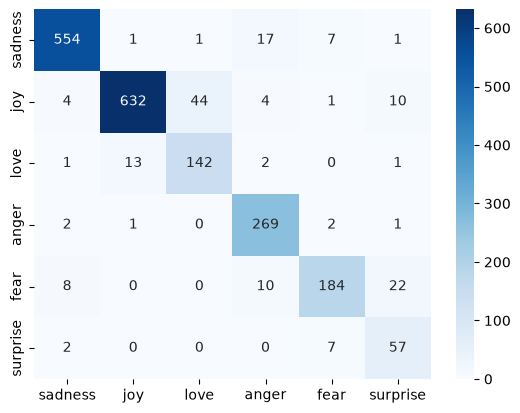

In [43]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence),axis = 1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions), annot = True, fmt = 'd', cmap = 'Blues', xticklabels = label_names, yticklabels = label_names)

### Final Predictions

In [45]:
# Test the winning model on unseen sample sentences

In [48]:
sample_sequences = tokenizer.texts_to_sequences(sample_texts)

sample_padded_sequences = pad_sequences(
    sample_sequences,
    maxlen=50,
    padding='post',
    truncating='post'
)

sample_predictions = np.argmax(
    BiGRU.predict(sample_padded_sequences),
    axis=1
)

for i in range(len(sample_texts)):

    print(
        f"Text: {sample_texts[i]}\n"
        f"Predicted Emotion: {label_names[sample_predictions[i]]}"
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Text: I can't believe how happy I am right now, this ia amazing
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minutes.
Predicted Emotion: anger
Text: I feel terrified when walking down dark allways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexcepted gift!
Predicted Emotion: surprise


# Save Model Evaluation

In [53]:
import os
import pickle

model_dir = 'Artifact'
os.makedirs(model_dir,exist_ok = True)

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir,'BiGRU_Model.keras'))

# Save the tokenizer Model
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
    pickle.dump(tokenizer, file)

            Server Start
               ⬇️
               ⬇️
            fastapi app creation
                ⬇️
                ⬇️
            lifespan event run
            ⬇️              ⬇️
Load BiGRU Model         load tokenizer
                   ⬇️
                   ⬇️

                api ready to use:        